# Лабораторная работа 11-12

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
df = pd.read_csv('ML-Dataset_cleaned.csv')

product_counts = df['ProductName'].value_counts()
rare_products = product_counts[product_counts < 5].index
df['ProductName'] = df['ProductName'].replace(rare_products, 'Other')

country_counts = df['CountryName'].value_counts()
rare_countries = country_counts[country_counts < 5].index
df['CountryName'] = df['CountryName'].replace(rare_countries, 'Other')

# Добавляем осмысленные взаимодействия
df['Price_Cost_Diff'] = df['ProductListPrice'] - df['ProductStandardCost']
df['Order_Value'] = df['PerUnitPrice'] * df['OrderItemQuantity']

target = 'TotalItemQuantity'

drop_cols = ['Profit', 'Profit_Std', 'Profit_Per_Unit',
             'CreditLimit_Norm', 'Category_Code', 'Job_Code']

X = df.drop(columns=[target] + drop_cols)
y = df[target]

# Удаляем экстремальные выбросы (опционально)
q1, q99 = y.quantile(0.01), y.quantile(0.99)
mask = (y >= q1) & (y <= q99)
X, y = X[mask], y[mask]

cat_cols = ['CountryName', 'EmployeeJobTitle', 'CategoryName', 'ProductName', 'Status']
num_cols = ['ProductStandardCost', 'ProductListPrice', 'CustomerCreditLimit',
            'OrderItemQuantity', 'PerUnitPrice', 'Price_Cost_Diff', 'Order_Value']

print(f"Целевая переменная: {target}")


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])


Целевая переменная: TotalItemQuantity



------------------------------------------------------------
Часть 1.1. Линейная регрессия (МНК)
------------------------------------------------------------
MSE:  1,751.67
RMSE: 41.85
MAE:  31.84
MAPE: 52.36%
R²:   0.6147

График остатков


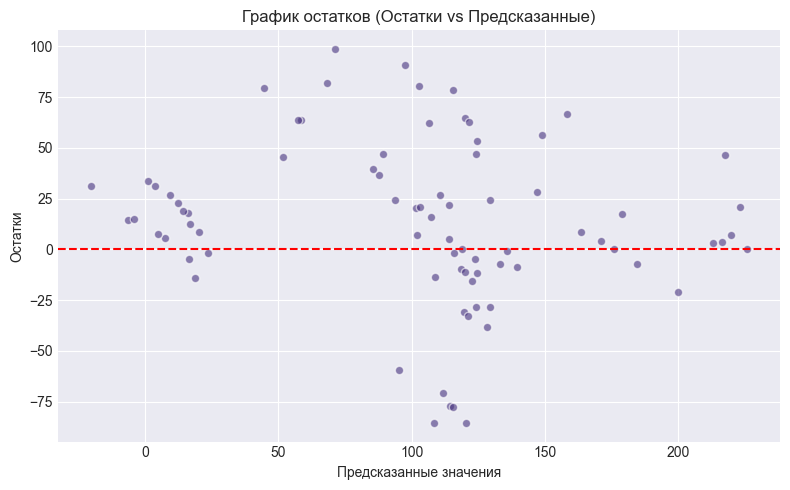

In [79]:
print("\n" + "-" * 60)
print("Часть 1.1. Линейная регрессия (МНК)")
print("-" * 60)

model_lr = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])
model_lr.fit(X_train, y_train)
y_pred_lr = model_lr.predict(X_test)

mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
mae_lr = mean_absolute_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)

def mape(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    mask = y_true != 0
    if mask.sum() == 0:
        return np.nan
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

mape_lr = mape(y_test, y_pred_lr)

print(f"MSE:  {mse_lr:,.2f}")
print(f"RMSE: {rmse_lr:,.2f}")
print(f"MAE:  {mae_lr:,.2f}")
print(f"MAPE: {mape_lr:.2f}%")
print(f"R²:   {r2_lr:.4f}")

# График остатков
print("\nГрафик остатков")

residuals = y_test.values - y_pred_lr

fig, ax = plt.subplots(1, 1, figsize=(8, 5))

ax.scatter(y_pred_lr, residuals, alpha=0.6, edgecolors='w')
ax.axhline(y=0, color='red', linestyle='--', linewidth=1.5)
ax.set_xlabel('Предсказанные значения')
ax.set_ylabel('Остатки')
ax.set_title('График остатков (Остатки vs Предсказанные)')
plt.tight_layout()
plt.show()

In [47]:
print("\n" + "-" * 60)
print("Часть 1.3. Регуляризация (Ridge и Lasso)")

alphas = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
ridge = GridSearchCV(
    Pipeline([('prep', preprocessor), ('reg', Ridge(random_state=42))]),
    {'reg__alpha': alphas}, cv=5, scoring='neg_mean_squared_error'
)
ridge.fit(X_train, y_train)
y_pred_ridge = ridge.predict(X_test)

lasso = GridSearchCV(
    Pipeline([('prep', preprocessor), ('reg', Lasso(max_iter=20000, random_state=42))]),
    {'reg__alpha': alphas}, cv=5, scoring='neg_mean_squared_error'
)
lasso.fit(X_train, y_train)
y_pred_lasso = lasso.predict(X_test)

mse_ridge = mean_squared_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mse_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

mse_lasso = mean_squared_error(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mse_lasso)
r2_lasso = r2_score(y_test, y_pred_lasso)

print(f"\nЛучший alpha для Ridge: {ridge.best_params_['reg__alpha']}")
print(f"Лучший alpha для Lasso: {lasso.best_params_['reg__alpha']}")

print("\n" + "-" * 75)
print(f"Сравнение метрик моделей")

print(f"{'Модель':<30} {'MSE':>8} {'RMSE':>8} {'R²':>8}")
print("-" * 58)
print(f"{'Линейная регрессия (МНК)':<30} {mse_lr:>8.2f} {rmse_lr:>8.2f} {r2_lr:>8.4f}")
print(f"{'Ridge-регрессия':<30} {mse_ridge:>8.2f} {rmse_ridge:>8.2f} {r2_ridge:>8.4f}")
print(f"{'Lasso-регрессия':<30} {mse_lasso:>8.2f} {rmse_lasso:>8.2f} {r2_lasso:>8.4f}")

print("-" * 75)
print(f"\n Интерпретация RMSE:")
print(f"  Среднее y_test = {y_test.mean():.1f}")
print(f"  RMSE = {rmse_lr:.1f} → ошибка составляет {rmse_lr/y_test.mean()*100:.1f}% от среднего")


------------------------------------------------------------
Часть 1.3. Регуляризация (Ridge и Lasso)

Лучший alpha для Ridge: 1.0
Лучший alpha для Lasso: 0.1

---------------------------------------------------------------------------
Сравнение метрик моделей
Модель                              MSE     RMSE       R²
----------------------------------------------------------
Линейная регрессия (МНК)        1751.67    41.85   0.6147
Ridge-регрессия                 1655.01    40.68   0.6360
Lasso-регрессия                 1606.77    40.08   0.6466
---------------------------------------------------------------------------

 Интерпретация RMSE:
  Среднее y_test = 115.8
  RMSE = 41.9 → ошибка составляет 36.1% от среднего


In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RANSACRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import scipy.stats as stats
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
df = pd.read_csv('ML-Dataset_cleaned.csv')

# Группировка редких категорий
product_counts = df['ProductName'].value_counts()
rare_products = product_counts[product_counts < 5].index
df['ProductName'] = df['ProductName'].replace(rare_products, 'Other')

country_counts = df['CountryName'].value_counts()
rare_countries = country_counts[country_counts < 5].index
df['CountryName'] = df['CountryName'].replace(rare_countries, 'Other')

# Инженерные признаки
df['Price_Cost_Diff'] = df['ProductListPrice'] - df['ProductStandardCost']
df['Order_Value'] = df['PerUnitPrice'] * df['OrderItemQuantity']

target = 'TotalItemQuantity'

drop_cols = ['Profit', 'Profit_Std', 'Profit_Per_Unit',
             'CreditLimit_Norm', 'Category_Code', 'Job_Code']

X = df.drop(columns=[target] + drop_cols)
y = df[target]

# Удаление выбросов по y
q1, q99 = y.quantile(0.01), y.quantile(0.99)
mask = (y >= q1) & (y <= q99)
X, y = X[mask], y[mask]

cat_cols = ['CountryName', 'EmployeeJobTitle', 'CategoryName', 'ProductName', 'Status']
num_cols = ['ProductStandardCost', 'ProductListPrice', 'CustomerCreditLimit',
            'OrderItemQuantity', 'PerUnitPrice', 'Price_Cost_Diff', 'Order_Value']


print(f"Размер данных: {X.shape}")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

# Базовый препроцессор
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])
X_train_base = preprocessor.fit_transform(X_train)
X_test_base = preprocessor.transform(X_test)


Размер данных: (395, 12)
Train: (316, 12), Test: (79, 12)


In [54]:
print("\n" + "-" * 60)
print("Базовые модели")
print("-" * 60)

# МНК
lr = LinearRegression()
lr.fit(X_train_base, y_train)
y_pred_lr = lr.predict(X_test_base)
mse_lr = mean_squared_error(y_test, y_pred_lr)
mae_lr = mean_absolute_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)
print(f"МНК — MSE: {mse_lr:.2f}, MAE: {mae_lr:.2f}, R²: {r2_lr:.4f}")

# Ridge
ridge_cv = GridSearchCV(Ridge(random_state=42), {'alpha': [0.1, 1.0, 10.0, 100.0]},
                        cv=5, scoring='neg_mean_squared_error')
ridge_cv.fit(X_train_base, y_train)
y_pred_ridge = ridge_cv.predict(X_test_base)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)
print(f"Ridge (α={ridge_cv.best_params_['alpha']}) — MSE: {mse_ridge:.2f}, MAE: {mae_ridge:.2f}, R²: {r2_ridge:.4f}")

# Lasso
lasso_cv = GridSearchCV(Lasso(max_iter=10000, random_state=42), {'alpha': [0.01, 0.1, 1.0, 10.0]},
                        cv=5, scoring='neg_mean_squared_error')
lasso_cv.fit(X_train_base, y_train)
y_pred_lasso = lasso_cv.predict(X_test_base)
mse_lasso = mean_squared_error(y_test, y_pred_lasso)
mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
r2_lasso = r2_score(y_test, y_pred_lasso)
print(f"Lasso (α={lasso_cv.best_params_['alpha']}) — MSE: {mse_lasso:.2f}, MAE: {mae_lasso:.2f}, R²: {r2_lasso:.4f}")

print("\n" + "-" * 60)
print("RANSAC (робастный метод)")
print("-" * 60)

ransac_params = [
    {'min_samples': 0.3, 'residual_threshold': 20},
    {'min_samples': 0.3, 'residual_threshold': 30},
    {'min_samples': 0.3, 'residual_threshold': 40},
    {'min_samples': 0.5, 'residual_threshold': 20},
    {'min_samples': 0.5, 'residual_threshold': 30},
    {'min_samples': 0.5, 'residual_threshold': 40},
    {'min_samples': 0.7, 'residual_threshold': 20},
    {'min_samples': 0.7, 'residual_threshold': 30},
    {'min_samples': 0.7, 'residual_threshold': 40},
]

best_ransac_mse = np.inf
best_ransac_model = None
best_ransac_params = {}

for params in ransac_params:
    try:
        ransac = RANSACRegressor(
            estimator=LinearRegression(),
            min_samples=params['min_samples'],
            residual_threshold=params['residual_threshold'],
            random_state=42,
            max_trials=200
        )
        ransac.fit(X_train_base, y_train)
        mse = mean_squared_error(y_test, ransac.predict(X_test_base))
        if mse < best_ransac_mse:
            best_ransac_mse = mse
            best_ransac_model = ransac
            best_ransac_params = params
    except:
        continue

y_pred_ransac = best_ransac_model.predict(X_test_base)
mse_ransac = mean_squared_error(y_test, y_pred_ransac)
mae_ransac = mean_absolute_error(y_test, y_pred_ransac)
r2_ransac = r2_score(y_test, y_pred_ransac)

print(f"Параметры: min_samples={best_ransac_params['min_samples']}, "
      f"residual_threshold={best_ransac_params['residual_threshold']}")
print(f"MSE: {mse_ransac:.2f}, MAE: {mae_ransac:.2f}, R²: {r2_ransac:.4f}")
print(f"Inliers: {best_ransac_model.inlier_mask_.sum()}/{len(y_train)}")



------------------------------------------------------------
Базовые модели
------------------------------------------------------------
МНК — MSE: 1751.67, MAE: 31.84, R²: 0.6147
Ridge (α=1.0) — MSE: 1655.01, MAE: 30.88, R²: 0.6360
Lasso (α=0.1) — MSE: 1606.77, MAE: 30.49, R²: 0.6466

------------------------------------------------------------
RANSAC (робастный метод)
------------------------------------------------------------
Параметры: min_samples=0.5, residual_threshold=30
MSE: 1496.87, MAE: 26.08, R²: 0.6708
Inliers: 217/316


In [61]:
print("\n" + "-" * 60)
print("Полиномиальные признаки + рабостаные методы")
print("-" * 60)

key_num_cols = ['OrderItemQuantity', 'Order_Value', 'Price_Cost_Diff']

# Индексы этих признаков в num_cols
key_indices = [num_cols.index(col) for col in key_num_cols]

scaler = StandardScaler()
X_train_key = scaler.fit_transform(X_train[key_num_cols].values)
X_test_key = scaler.transform(X_test[key_num_cols].values)

poly = PolynomialFeatures(degree=2, include_bias=False, interaction_only=False)
X_train_poly = poly.fit_transform(X_train_key)
X_test_poly = poly.transform(X_test_key)

poly_feature_names = poly.get_feature_names_out(key_num_cols)

other_num_cols = [col for col in num_cols if col not in key_num_cols]
X_train_other = scaler.fit_transform(X_train[other_num_cols].values)
X_test_other = scaler.transform(X_test[other_num_cols].values)

ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
X_train_cat = ohe.fit_transform(X_train[cat_cols])
X_test_cat = ohe.transform(X_test[cat_cols])

X_train_final = np.hstack([X_train_poly, X_train_other, X_train_cat])
X_test_final = np.hstack([X_test_poly, X_test_other, X_test_cat])

scaler_all = StandardScaler()
X_train_final = scaler_all.fit_transform(X_train_final)
X_test_final = scaler_all.transform(X_test_final)

# Обычная полиномиальная регрессия (МНК с полиномами)
print("\n--- Обычная полиномиальная регрессия (МНК + Poly) ---")
poly_lr = Ridge(alpha=0.01, random_state=42)  # Слабая регуляризация для стабильности
poly_lr.fit(X_train_final, y_train)
y_pred_poly_lr = poly_lr.predict(X_test_final)
mse_poly_lr = mean_squared_error(y_test, y_pred_poly_lr)
mae_poly_lr = mean_absolute_error(y_test, y_pred_poly_lr)
r2_poly_lr = r2_score(y_test, y_pred_poly_lr)
print(f"MSE: {mse_poly_lr:.2f}, MAE: {mae_poly_lr:.2f}, R²: {r2_poly_lr:.4f}")

# Робастная полиномиальная регрессия (RANSAC + Poly)
print("\n--- Робастная полиномиальная регрессия (RANSAC + Poly) ---")
best_poly_ransac_mse = np.inf
best_poly_ransac = None
best_poly_ransac_params = {}

for min_s in [0.5, 0.6, 0.7]:
    for res_t in [20, 30, 40]:
        try:
            poly_ransac = RANSACRegressor(
                estimator=LinearRegression(),
                min_samples=min_s,
                residual_threshold=res_t,
                random_state=42,
                max_trials=200
            )
            poly_ransac.fit(X_train_final, y_train)
            mse = mean_squared_error(y_test, poly_ransac.predict(X_test_final))
            if mse < best_poly_ransac_mse:
                best_poly_ransac_mse = mse
                best_poly_ransac = poly_ransac
                best_poly_ransac_params = {'min_samples': min_s, 'residual_threshold': res_t}
        except:
            continue

y_pred_poly_ransac = best_poly_ransac.predict(X_test_final)
mse_poly_ransac = mean_squared_error(y_test, y_pred_poly_ransac)
mae_poly_ransac = mean_absolute_error(y_test, y_pred_poly_ransac)
r2_poly_ransac = r2_score(y_test, y_pred_poly_ransac)
print(f"Параметры: min_samples={best_poly_ransac_params['min_samples']}, "
      f"residual_threshold={best_poly_ransac_params['residual_threshold']}")
print(f"MSE: {mse_poly_ransac:.2f}, MAE: {mae_poly_ransac:.2f}, R²: {r2_poly_ransac:.4f}")


------------------------------------------------------------
Полиномиальные признаки + рабостаные методы
------------------------------------------------------------

--- Обычная полиномиальная регрессия (МНК + Poly) ---
MSE: 1888.90, MAE: 32.63, R²: 0.5846

--- Робастная полиномиальная регрессия (RANSAC + Poly) ---
Параметры: min_samples=0.5, residual_threshold=40
MSE: 1573.92, MAE: 26.19, R²: 0.6538



------------------------------------------------------------------------------------------
Сравнение всех моделей
------------------------------------------------------------------------------------------
Модель                                               MSE      MAE       R²
---------------------------------------------------------------------------
1. Линейная регрессия (МНК)                      1751.67    31.84   0.6147
2. Ridge-регрессия                               1655.01    30.88   0.6360
3. Lasso-регрессия                               1606.77    30.49   0.6466
4. RANSAC (робастная)                            1496.87    26.08   0.6708
5. МНК + Poly2 (полиномиальная)                  1888.90    32.63   0.5846
6. RANSAC + Poly2 (робастная полином.)           1573.92    26.19   0.6538

Лучшая по MSE: 4. RANSAC (робастная) (MSE = 1496.87)
Лучшая по R²:  4. RANSAC (робастная) (R² = 0.6708)

Сравнение трёх подходов
---------------------------------------------------------------

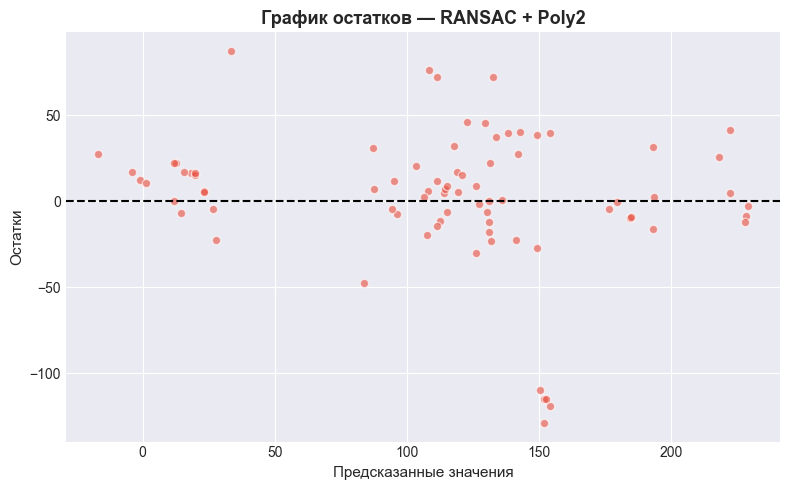


------------------------------------------------------------
Сводный график: Фактические vs Предсказанные значения
------------------------------------------------------------


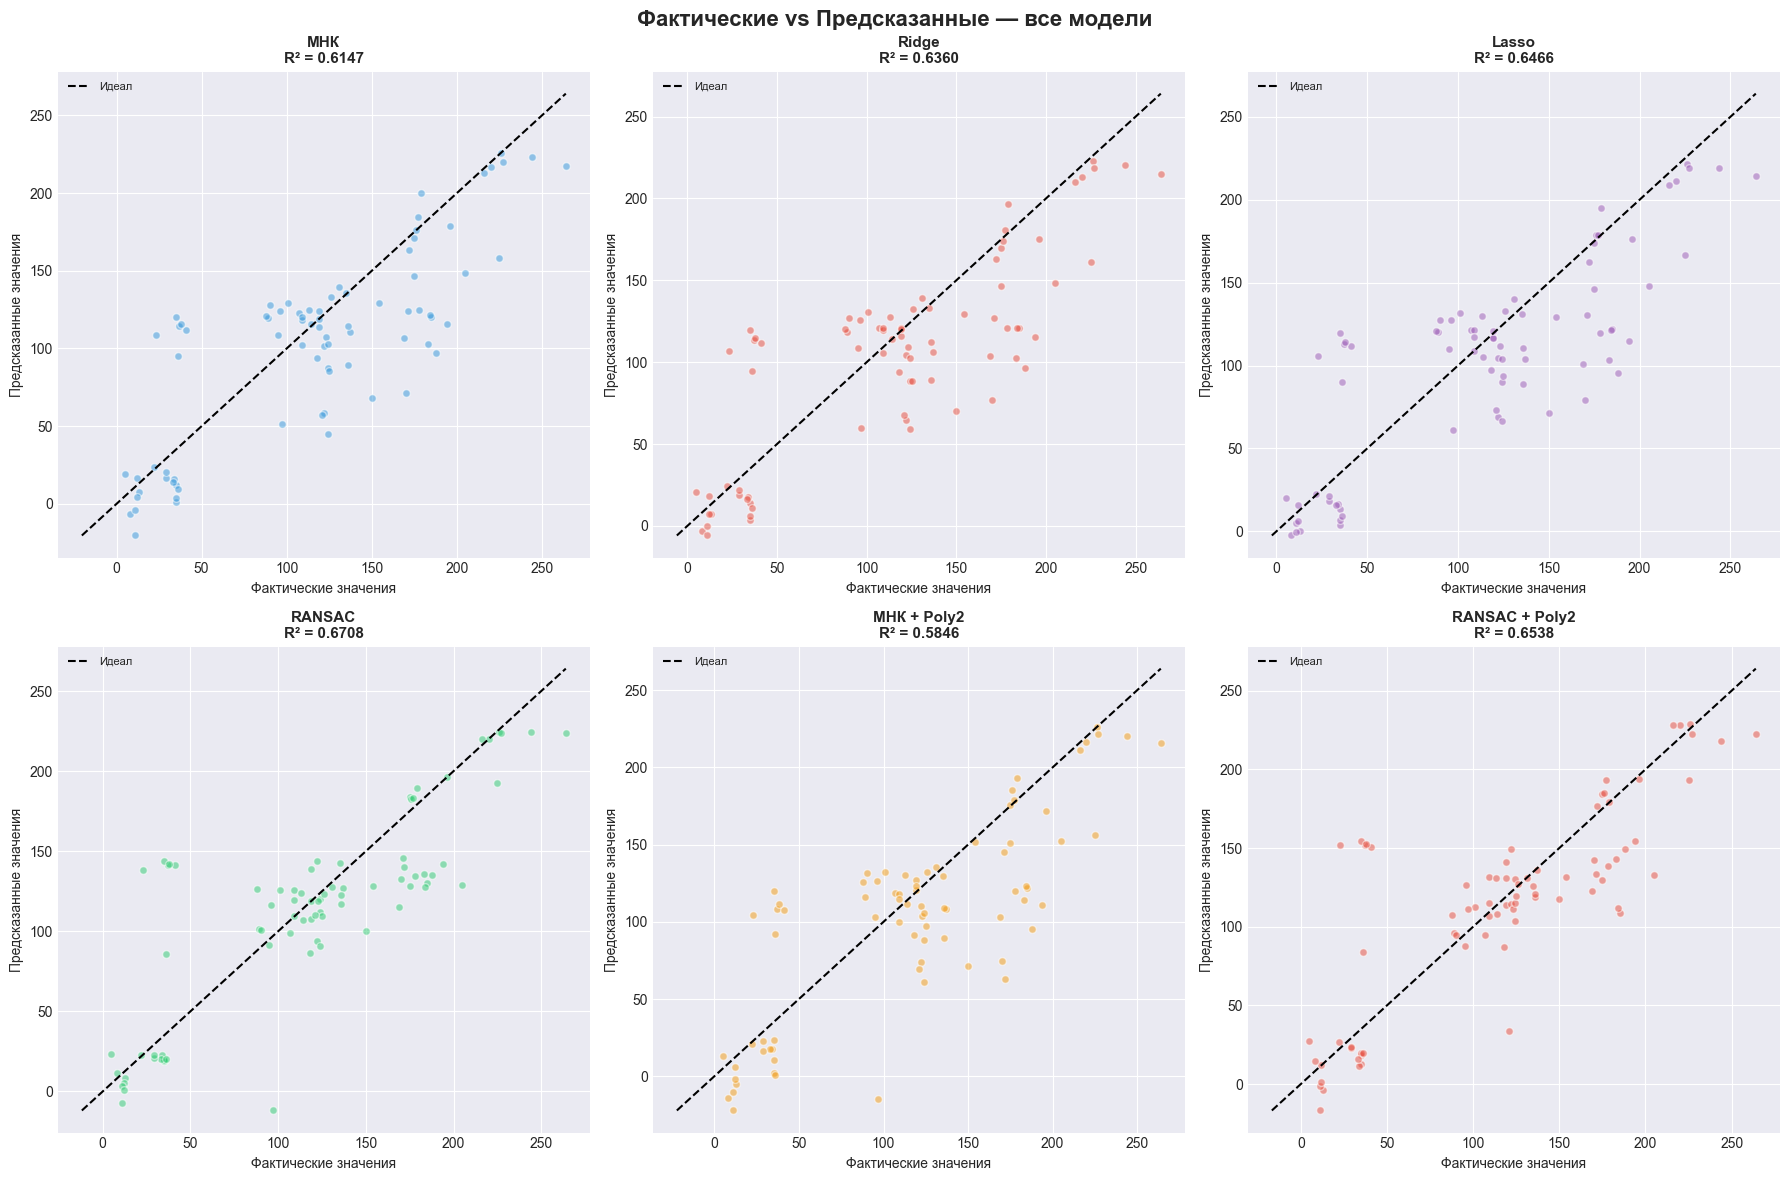

In [81]:
print("\n" + "-" * 90)
print("Сравнение всех моделей")
print("-" * 90)
print(f"{'Модель':<45} {'MSE':>10} {'MAE':>8} {'R²':>8}")
print("-" * 75)

results = [
    ('1. Линейная регрессия (МНК)', mse_lr, mae_lr, r2_lr),
    ('2. Ridge-регрессия', mse_ridge, mae_ridge, r2_ridge),
    ('3. Lasso-регрессия', mse_lasso, mae_lasso, r2_lasso),
    ('4. RANSAC (робастная)', mse_ransac, mae_ransac, r2_ransac),
    ('5. МНК + Poly2 (полиномиальная)', mse_poly_lr, mae_poly_lr, r2_poly_lr),
    ('6. RANSAC + Poly2 (робастная полином.)', mse_poly_ransac, mae_poly_ransac, r2_poly_ransac),
]

for name, mse, mae, r2 in results:
    print(f"{name:<45} {mse:>10.2f} {mae:>8.2f} {r2:>8.4f}")

# Лучшая модель
best_by_mse = min(results, key=lambda x: x[1])
best_by_r2 = max(results, key=lambda x: x[3])
print(f"\nЛучшая по MSE: {best_by_mse[0]} (MSE = {best_by_mse[1]:.2f})")
print(f"Лучшая по R²:  {best_by_r2[0]} (R² = {best_by_r2[3]:.4f})")

# Сравнение трёх подходов
print("\n" + "Сравнение трёх подходов")
print("-" * 70)

best_no_poly = min([('RANSAC', mse_ransac, r2_ransac),
                    ('Lasso', mse_lasso, r2_lasso),
                    ('Ridge', mse_ridge, r2_ridge)], key=lambda x: x[1])

print(f"{'Подход':<50} {'MSE':>10} {'R²':>8}")
print(f"{'1. Обычная полиномиальная (МНК + Poly2)':<50} {mse_poly_lr:>10.2f} {r2_poly_lr:>8.4f}")
print(f"{'2. Робастная полиномиальная (RANSAC + Poly2)':<50} {mse_poly_ransac:>10.2f} {r2_poly_ransac:>8.4f}")
print(f"{'3. Лучший без полиномов (' + best_no_poly[0] + ')':<50} {best_no_poly[1]:>10.2f} {best_no_poly[2]:>8.4f}")

# График остатков для робастной полиномиальной модели
print("\n" + "-" * 60)
print("График остатков для робастной полиномиальной модели")
print("-" * 60)

residuals_poly_ransac = y_test.values - y_pred_poly_ransac

fig, ax = plt.subplots(1, 1, figsize=(8, 5))
ax.scatter(y_pred_poly_ransac, residuals_poly_ransac, alpha=0.6, edgecolors='w', color='#e74c3c')
ax.axhline(y=0, color='black', linestyle='--', linewidth=1.5)
ax.set_xlabel('Предсказанные значения', fontsize=11)
ax.set_ylabel('Остатки', fontsize=11)
ax.set_title('График остатков — RANSAC + Poly2', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('residuals_ransac_poly2.png', dpi=150, bbox_inches='tight')
plt.show()

# Сводный график: Факт vs Предсказанные (ВСЕ модели)
print("\n" + "-" * 60)
print("Сводный график: Фактические vs Предсказанные значения")
print("-" * 60)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

all_preds = [
    ('МНК', y_pred_lr, '#3498db'),
    ('Ridge', y_pred_ridge, '#e74c3c'),
    ('Lasso', y_pred_lasso, '#9b59b6'),
    ('RANSAC', y_pred_ransac, '#2ecc71'),
    ('МНК + Poly2', y_pred_poly_lr, '#f39c12'),
    ('RANSAC + Poly2', y_pred_poly_ransac, '#e74c3c'),
]

for i, (name, yp, color) in enumerate(all_preds):
    ax = axes[i]
    ax.scatter(y_test, yp, alpha=0.5, edgecolors='w', s=30, color=color)
    mn = min(y_test.min(), yp.min())
    mx = max(y_test.max(), yp.max())
    ax.plot([mn, mx], [mn, mx], 'k--', linewidth=1.5, label='Идеал')
    ax.set_xlabel('Фактические значения', fontsize=10)
    ax.set_ylabel('Предсказанные значения', fontsize=10)
    ax.set_title(f'{name}\nR² = {r2_score(y_test, yp):.4f}', fontsize=11, fontweight='bold')
    ax.legend(fontsize=8)

plt.suptitle('Фактические vs Предсказанные — все модели', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('all_models_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

RANSAC:  улучшил R²


Робастность полезна в сочетании с полиномами для учёта нелинейности


Для этого датасета RANSAC (без полиномов) показал наилучший результат